# House Price Prediction (Data cleaning and EDA)

### 1. Importing Libraries and Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import mutual_info_regression

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

In [2]:
df = pd.read_csv("data_files/train.csv")

### 2. Data Overview

In [3]:
print("Shape of dataframe:", df.shape)

Shape of dataframe: (1460, 81)


In [4]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
print(f"Total duplicated values: {df.duplicated().sum()}")

Total duplicated values: 0


In [6]:
print(f"Total missing values: {df.isnull().sum().sum()}")

Total missing values: 7829


In [7]:
# Generate a summary of the entire dataset
dataset_summary = pd.DataFrame({
    "dtype": df.dtypes,
    "missing": df.isnull().sum(),
    "missing %": df.isnull().mean() * 100,
    "unique": df.nunique()
})

dataset_summary.sort_values("missing %", ascending=False)

,dtype,missing,missing %,unique
PoolQC,object,1453,99.520548,3
MiscFeature,object,1406,96.301370,4
Alley,object,1369,93.767123,2
Fence,object,1179,80.753425,4
MasVnrType,object,872,59.726027,3
FireplaceQu,object,690,47.260274,5
LotFrontage,float64,259,17.739726,110
GarageYrBlt,float64,81,5.547945,97
GarageCond,object,81,5.547945,5
GarageType,object,81,5.547945,6


In [8]:
# Separate into numeric and categorical columns
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns

print(f"Number of numerical columns: {len(num_cols)}")
print(f"Number of categorical columns: {len(cat_cols)}")

Number of numerical columns: 38
Number of categorical columns: 43


### 3. Target Variable Analysis

In [9]:
df["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

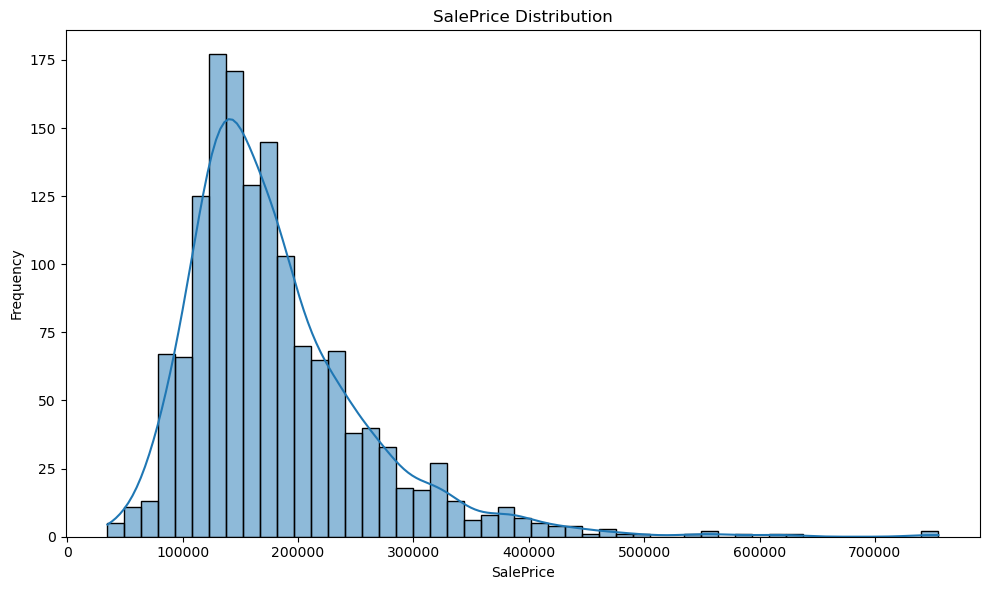

In [10]:
# Visualising the distribution of SalePrice
plt.figure(figsize=(10, 6))
sns.histplot(df["SalePrice"], kde=True)
plt.title("SalePrice Distribution")
plt.xlabel("SalePrice")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

The distribution of the SalePrice is positively skewed  (right-skewed), indicating that a small number of properties have significantly higher sale prices than the majority of homes. Since many regression algorithms perform better when the target variable is closer to a normal distribution, a natural log transformation will be considered during data preprocessing.

### 4. Missing Value Analysis

In [11]:
missing = (
    df.isnull().sum().sort_values(ascending=False)
)
missing[missing > 0]

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

Based on the data_description.txt, missing values in several features such as PoolQC, MiscFeature, Alley, Fence, MasVnrType, FireplaceQu, garage-related variables and basement-related variables represent *structural missingness*. These indicate the absence of the corresponding amenity rather than true missing data. 

**Imputation strategy:**
 - Categorical features --> fill with **'No_Amenity'**
 - Numerical features --> fill with **0** where absence is meaningfully represented

---

In contrast, Electrical, LotFrontage and MasVnrArea are treated as true missing values and handled separately. The missing values (NA) imply unknown or unrecorded data, rather than indiciating that the property does not have the corresponding feature.

**Imputation strategy:**
 - Categorical features --> fill with **mode**
 - Numerical features   --> fill with **median**

### 5. Numerical Feature Analysis
1) Distribution Analysis
2) Outlier Inspection
3) Correlation with SalePrice (target variable)
4) Key observations (skewness, outliers, correlation with SalePrice, weak/noisy variables)

In [12]:
# Correlation Analysis with SalePrice
saleprice_corr = (
    df[num_cols].corr()["SalePrice"].sort_values(ascending=False)
)
saleprice_corr

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

SalePrice exhibits strong positive correlations with OverallQual (0.79), GrLivArea (0.71), GarageCars (0.64), GarageArea (0.62),TotalBsmtSF (0.61). This suggests that overall house quality, living area, garage capacity and basement size are important drivers of house prices.

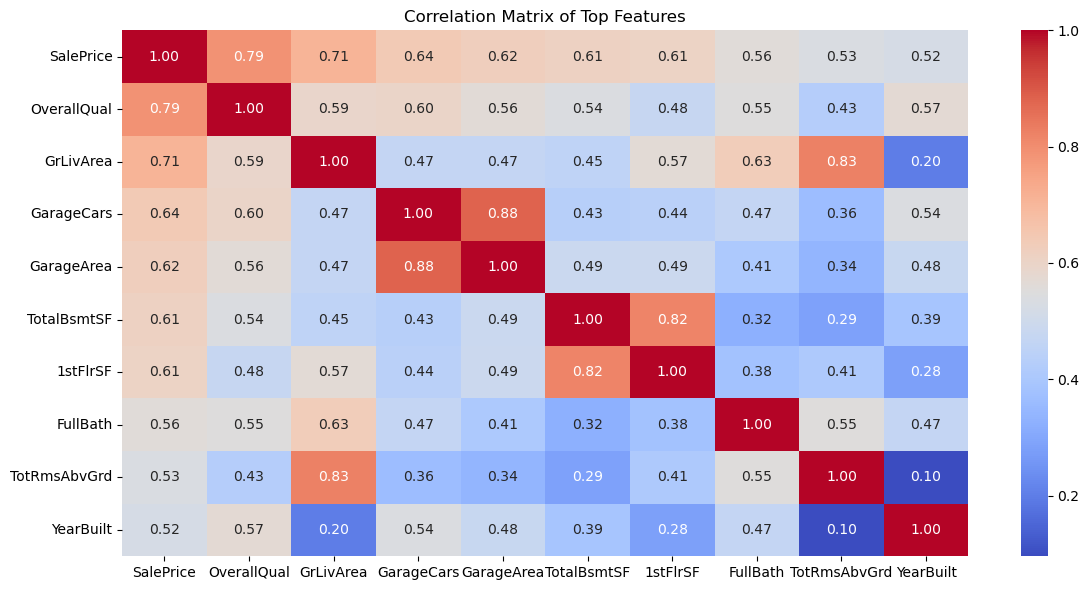

In [13]:
# Heatmap of top 10 numerical features
top10_num_features = saleprice_corr.head(10).index

corr_matrix = df[top10_num_features].corr()

plt.figure(figsize=(12, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Matrix of Top Features")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

**Strong relationships**
 - GarageArea and GarageCars are highly correlated (0.88)
 - TotRmsAbvGrd and GrLivArea are highly correlated (0.83)
 - 1stFlrSF and TotalBsmtSF are highly correlated (0.82) <br>
These relationships suggest potential redundency among certain numerical features and should be considered during feature engineering and model development.

**Weak relationships**
 - YearBuilt and TotRmsAbvGrd are weakly correlated (0.10)
 - YearBuilt and GrLivArea are weakly correlated (0.20) <br>
These suggests that house age is not strongly associated with property size.

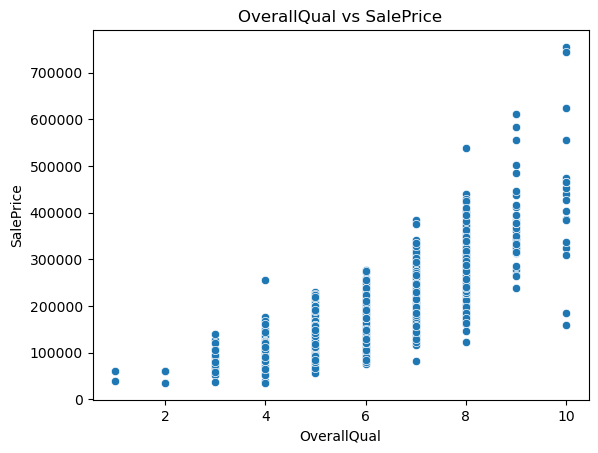

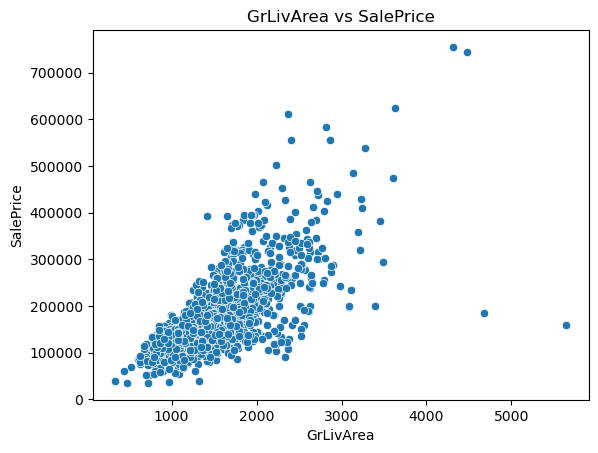

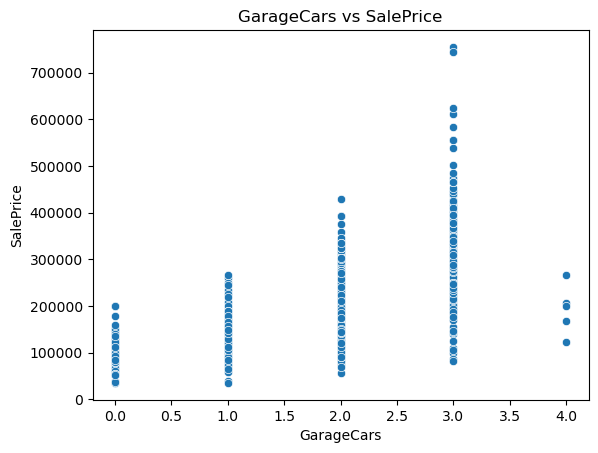

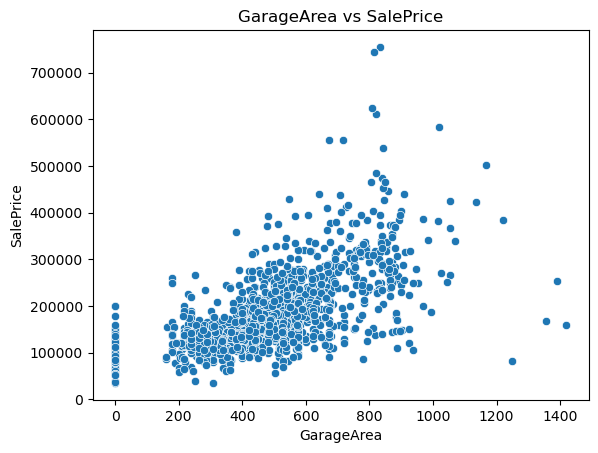

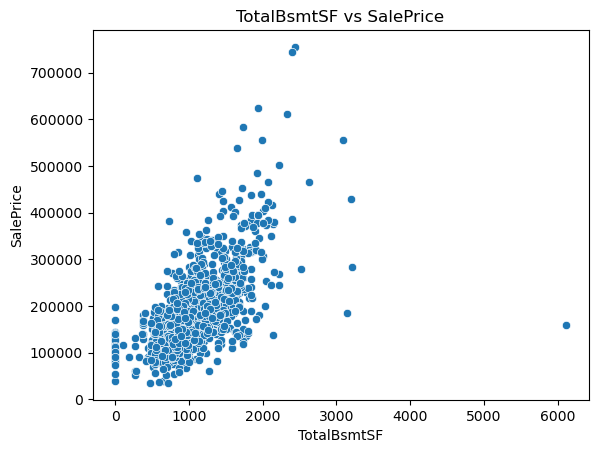

In [14]:
top_num_features = saleprice_corr.drop("SalePrice").head(5).index
for feature in top_num_features:
    sns.scatterplot(data=df, x=feature, y="SalePrice")
    plt.title(f"{feature} vs SalePrice")
    plt.show()

**Observations from scatterplots:**
 - *OverallQual and SalePrice*: Strong positive relationship with a clear upward trend and a few outliers.
 - *GrLivArea and SalePrice*: Strong positive relationship with some extreme outliers.
 - *GarageCars and SalePrice*: Moderate positive relationship with outliers for 4-cars garages.
 - *GarageArea and SalePrice*: Moderate positive relationship with some unusually large garages areas at moderate prices.
 - *TotalBsmtSF and SalePrice*: Moderate positive relationship with extreme values.

**Summary** <br>
OverallQual and GrLivArea appears to have the strongest marginal predictors with SalePrice. In contrast, GarageCars, GarageArea and TotalBsmtSF have a higher variability, suggesting comparatively weaker predictive strength.

### 6. Categorical Feature Analysis

In [15]:
cat_groups = {
    "sale": ["SaleType", "SaleCondition"],
    "basement": ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"],
    "garage": ["GarageType", "GarageFinish", "GarageQual", "GarageCond"],
    "quality": ["ExterQual", "ExterCond", "HeatingQC", "KitchenQual", "FireplaceQu", "PoolQC", "Functional"],
    "location": ["MSZoning", "Neighborhood", "Condition1", "Condition2"],
    "exterior": ["RoofStyle", "RoofMatl", "Exterior1st", "Exterior2nd"],
    "lot": ["Street", "Alley", "LotShape", "LandContour", "LotConfig", "LandSlope", "PavedDrive", "Fence"],
    "utilities": ["Utilities", "Heating", "CentralAir", "Electrical"],
    "structure": ["HouseStyle", "BldgType", "MasVnrType", "Foundation"],
    "others": ["MiscFeature"]
}

In [16]:
# Encoding categoricial features temporarily
df_temp = df.copy()

for col in cat_cols:
    df_temp[col] = LabelEncoder().fit_transform(df_temp[col].astype(str))

# Compute Mutual Information (MI) scores
mi_X = df_temp[cat_cols]
mi_y = df_temp["SalePrice"]

mi_scores = mutual_info_regression(
    mi_X, mi_y,
    random_state=42
)
mi_rank = pd.Series(mi_scores, index=cat_cols).sort_values(ascending=False)

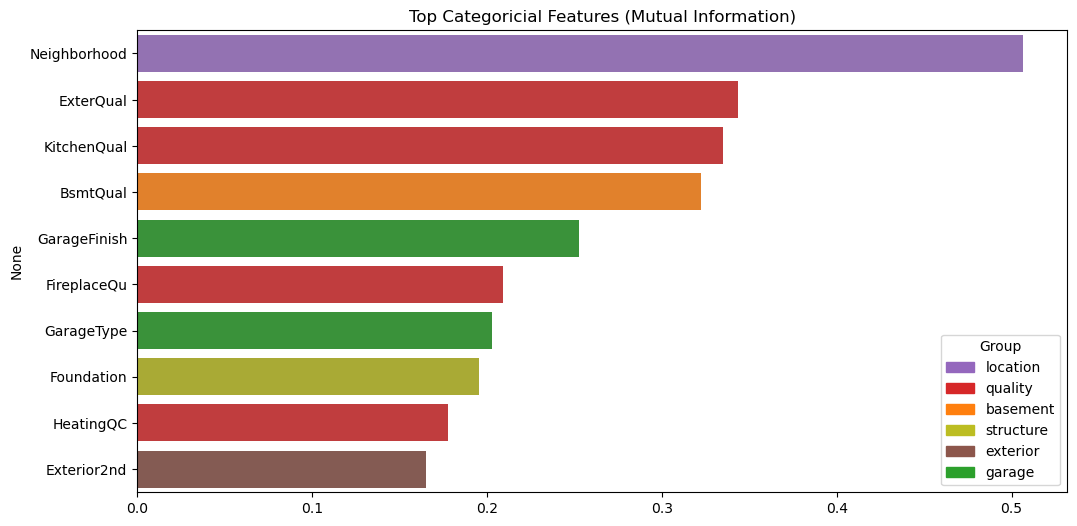

In [17]:
top10_cat_features = mi_rank.head(10)

# Map each column to its group
col_to_group = {
    col: group
    for group, cols in cat_groups.items()
    for col in cols
}

# Assign colours to groups
groups = list(cat_groups.keys())
palette = sns.color_palette("tab10", len(groups))
group_to_colour = dict(zip(groups, palette))

# Get the colour of each bar based on its group
bar_colours = [
    group_to_colour[col_to_group[feat]]
    for feat in top10_cat_features.index
]

# Bar chart of top 10 categoricial features
plt.figure(figsize=(12, 6))
sns.barplot(x=top10_cat_features.values, y=top10_cat_features.index, hue=top10_cat_features.index, palette=bar_colours,)

# Add legend showing only groups present in this chart
present_groups = set(col_to_group[f] for f in top10_cat_features.index)
handles = [plt.Rectangle((0,0),1,1, color=group_to_colour[g]) for g in present_groups]
plt.legend(handles, present_groups, title="Group")

plt.title("Top Categoricial Features (Mutual Information)")
plt.show()

In [18]:
group_scores = {}

for group, cols in cat_groups.items():
    cols = [c for c in cols if c in cat_cols]
    group_scores[group] = mi_rank[cols].mean()

pd.Series(group_scores).sort_values(ascending=False)

location     0.159916
quality      0.152185
garage       0.148385
basement     0.130240
structure    0.105565
exterior     0.080941
sale         0.077960
lot          0.032351
utilities    0.031449
others       0.000000
dtype: float64

The Mutual Information analysis shows only a small subset of the categorical features carry predictive signal. **Neighborhood** is the most important feature, indicating that location has the strongest impact on price. Quality-related features such as **ExterQual**, **KitchenQual**, and **BsmtQual** also show strong influence, highlighting the importance of overall house quality.

Overall the results suggest that price is mainly influenced by *location and quality-related features*.

### 7. Data Cleaning

In [19]:
df_clean = df.copy()

# Encoding categoricial features with structural missingness
cat_cols_to_impute = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "MasVnrType", "FireplaceQu", "GarageCond", "GarageType", "GarageFinish", "GarageQual", "BsmtFinType2", "BsmtExposure", "BsmtQual", "BsmtCond", "BsmtFinType1", 
]
num_cols_to_impute = [
    "GarageYrBlt"
]

for col in cat_cols_to_impute:
    df_clean[col] = df_clean[col].fillna("No_Amenity")

for col in num_cols_to_impute:
    df_clean[col] = df_clean[col].fillna(0)

NOTE: LotFrontage, MasVnrArea, Electrical are left NaN here on purpose. 
 - For modelling, they will be imputed later on the training dataset to ensure no data leakage in the [price_regression_model](price_regression_model.ipynb) notebook. 
 - For visualisation, these columns will be imputed normally at the end of the notebook.

In [20]:
# Validate year fields
year_checks = {
    "GarageYrBlt > YrSold": df_clean[(df_clean["GarageYrBlt"] > df_clean["YrSold"]) & (df_clean["GarageYrBlt"] != 0)],
    "YearRemodAdd < YearBuilt": df_clean[df_clean["YearRemodAdd"] < df_clean["YearBuilt"]],
    "YearBuilt > YrSold": df_clean[df_clean["YearBuilt"] > df_clean["YrSold"]],
    "GarageYrBlt < YearBuilt": df_clean[(df_clean["GarageYrBlt"] < df_clean["YearBuilt"]) & (df_clean["GarageYrBlt"] != 0)],
    "YearRemodAdd > YrSold": df_clean[df_clean["YearRemodAdd"] > df_clean["YrSold"]],
}

for name, row in year_checks.items():
    print(f"{name}: {len(row)} rows")
    if len(row):
        display(row[["YearBuilt", "YearRemodAdd", "GarageYrBlt", "YrSold"]])

GarageYrBlt > YrSold: 0 rows
YearRemodAdd < YearBuilt: 0 rows
YearBuilt > YrSold: 0 rows
GarageYrBlt < YearBuilt: 9 rows


,YearBuilt,YearRemodAdd,GarageYrBlt,YrSold
29,1927,1950,1920.0,2008
93,1910,1998,1900.0,2007
324,1967,2007,1961.0,2010
600,2005,2005,2003.0,2006
736,1950,1950,1949.0,2006
1103,1959,1959,1954.0,2006
1376,1930,1950,1925.0,2008
1414,1923,2000,1922.0,2008
1418,1963,1963,1962.0,2008


YearRemodAdd > YrSold: 1 rows


,YearBuilt,YearRemodAdd,GarageYrBlt,YrSold
523,2007,2008,2007.0,2007


Leaving the 9 rows of GarageYrBlt < YearBuilt anomaly ***as it is*** as a garage could be built before the main house, so it is treated as a legitimate data pattern.

Leaving the 1 row of YearRemodAdd > YrSold anomaly ***as it is*** as it is most likely a data entry error. This issue only affects one observation and there is insufficient information to determine the correct value, so it is left untouched to avoid introducing an unsupported assumption.

In [21]:
# Changing dtype of MSSubClass (numerical-coded categoricals)
df_clean["MSSubClass"] = df_clean["MSSubClass"].astype(str)

In [22]:
# Ordinal-encode quality/condition scale columns
qual_cols = [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC", 
]

for col in qual_cols:
    df_clean[f"{col}_original"] = df_clean[col].copy()
    df_clean[col] = df_clean[col].map(
        {"No_Amenity": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
    ).astype(int)

In [23]:
# Removing Outliers (De Cock (2011) identifies houses with GrLivArea > 4000 sq ft as potential outliers)
outlier_idx = df_clean[(df_clean["GrLivArea"] > 4000)].index
df_clean = df_clean.drop(index=outlier_idx)
print(f"Dropped {len(outlier_idx)} outlier rows\n")

# Check for inconsistencies
quality_attribute_pairs = {
    "Basement":     ("BsmtQual", "TotalBsmtSF"),
    "Garage":       ("GarageQual", "GarageArea"),
    "Fireplace":    ("FireplaceQu", "Fireplaces"),
    "Pool":         ("PoolQC", "PoolArea"),
}
for name, (qual_col, area_col) in quality_attribute_pairs.items():
    # After ordinal encoding, "No_Amenity" = 0
    qual_nil_area_present = df_clean[
        (df_clean[qual_col] == 0) & (df_clean[area_col] > 0)
    ]
    qual_present_area_nil = df_clean[
        (df_clean[qual_col] != 0) & (df_clean[area_col] == 0)
    ]

    print(
        f"{name}: qual=No_Amenity but area > 0 --> {len(qual_nil_area_present)} rows | "
        f"qual!=No_Amenity but area = 0 --> {len(qual_present_area_nil)} rows"
    )

type_present_area_nil = df_clean[
    (df_clean["MasVnrType"] != "No_Amenity") & (df_clean["MasVnrArea"] == 0)
]
type_nil_area_present = df_clean[
    (df_clean["MasVnrType"] == "No_Amenity") & (df_clean["MasVnrArea"] > 0)
]

print(
    f"Masonry Veneer: type!=No_Amenity but area = 0 --> {len(type_present_area_nil)} rows | "
    f"type=No_Amenity but area > 0 --> {len(type_nil_area_present)} rows"
)

Dropped 4 outlier rows

Basement: qual=No_Amenity but area > 0 --> 0 rows | qual!=No_Amenity but area = 0 --> 0 rows
Garage: qual=No_Amenity but area > 0 --> 0 rows | qual!=No_Amenity but area = 0 --> 0 rows
Fireplace: qual=No_Amenity but area > 0 --> 0 rows | qual!=No_Amenity but area = 0 --> 0 rows
Pool: qual=No_Amenity but area > 0 --> 0 rows | qual!=No_Amenity but area = 0 --> 0 rows
Masonry Veneer: type!=No_Amenity but area = 0 --> 2 rows | type=No_Amenity but area > 0 --> 5 rows


In [24]:
# Visualing the data inconsistency with Masonry Veneer
display(type_present_area_nil[["MasVnrType", "MasVnrArea", "SalePrice"]])
display(type_nil_area_present[["MasVnrType", "MasVnrArea", "Exterior1st", "Exterior2nd", "SalePrice"]])

,MasVnrType,MasVnrArea,SalePrice
688,BrkFace,0.0,392000
1241,Stone,0.0,248328


,MasVnrType,MasVnrArea,Exterior1st,Exterior2nd,SalePrice
624,No_Amenity,288.0,VinylSd,VinylSd,165150
773,No_Amenity,1.0,Wd Sdng,Wd Sdng,114500
1230,No_Amenity,1.0,Plywood,Plywood,190000
1300,No_Amenity,344.0,VinylSd,VinylSd,225000
1334,No_Amenity,312.0,HdBoard,HdBoard,125000


Approach taken to deal with the data inconsistency of Masonry Veneer:
 - Treat MasVnrArea = 0 as reliable and correct MasVnrType to "No_Amenity" rather than dropping the rows. [type!=No_Amenity but area = 0] (2 rows)
 - Treat MasVnrArea > 0 as reliable and change MasVnrType from "No_Amenity" to "Unknown" since an area measurement is stronger evidence that masonry veneer exists [type=No_Amenity but area > 0] (5 rows)

In [25]:
# Correcting rows where no mas vnr area exists
df_clean.loc[
    (df_clean["MasVnrType"] != "No_Amenity") & (df_clean["MasVnrArea"] == 0), 
    "MasVnrType"
] = "No_Amenity"

# Correct rows where mas vnr exists but type is "No_Amenity"
df_clean.loc[
    (df_clean["MasVnrType"] == "No_Amenity") & (df_clean["MasVnrArea"] > 0), 
    "MasVnrType"
] = "Unknown"

In [26]:
print("Remaining missing values:", df_clean.isnull().sum().sum()) # Should have 268 (259 + 8 + 1) from the true missing values
print("Shape after cleaning", df_clean.shape)

Remaining missing values: 268
Shape after cleaning (1456, 91)


### 8. Feature Engineering
1) Log transformation of SalePrice
2) Derive features (size, age, quality, amenities)

In [27]:
# Log-transform SalePrice
df_clean["SalePrice_log"] = np.log1p(df_clean["SalePrice"])

In [28]:
# Deriving features based on size
df_clean["TotalSF"] = df_clean["TotalBsmtSF"] + df_clean["1stFlrSF"] + df_clean["2ndFlrSF"]
df_clean["LivAreaPerRoom"] = df_clean["GrLivArea"] / df_clean["TotRmsAbvGrd"].replace(0, np.nan)
df_clean["TotalBath"] = df_clean["FullBath"] + 0.5*df_clean["HalfBath"] + df_clean["BsmtFullBath"] + 0.5*df_clean["BsmtHalfBath"]
df_clean["TotalPorchSF"] = df_clean["OpenPorchSF"] + df_clean["EnclosedPorch"] + df_clean["3SsnPorch"] + df_clean["ScreenPorch"]

df_clean["LivAreaPerRoom"] = df_clean["LivAreaPerRoom"].fillna(0)


# Deriving features based on age
df_clean["HouseAge"] = df_clean["YrSold"] - df_clean["YearBuilt"]
df_clean["RemodAge"] = df_clean["YrSold"] - df_clean["YearRemodAdd"]
df_clean["GarageAge"] = np.where(
    df_clean["GarageYrBlt"] == 0, -1, df_clean["YrSold"] - df_clean["GarageYrBlt"]
) # handles houses without garages
df_clean["IsNew"] = (df_clean["YrSold"] == df_clean["YearBuilt"]).astype(int)

# Deriving features based on quality
df_clean["OverallGrade"] = df_clean["OverallQual"] * df_clean["OverallCond"]
df_clean["QualitySF"] = df_clean["OverallQual"] * df_clean["GrLivArea"]


# Deriving features based on amenities (binary flags)
df_clean["HasGarage"] = (df_clean["GarageArea"] > 0).astype(int)
df_clean["HasFireplace"] = (df_clean["Fireplaces"] > 0).astype(int)
df_clean["Has2ndFlr"] = (df_clean["2ndFlrSF"] > 0).astype(int)
df_clean["HasBsmt"] = (df_clean["TotalBsmtSF"] > 0).astype(int)

print("Number of missing values after feature engineering:", df_clean.isnull().sum().sum()) # Should have 268 (259 + 8 + 1) from the true missing values

Number of missing values after feature engineering: 268


In [29]:
# Correlation check against Saleprice
feature_eng_cols = (
    df_clean.select_dtypes(include="number")
    .columns
    .difference(num_cols)
)

saleprice_log_corr = (
    df_clean[feature_eng_cols].corr()["SalePrice_log"].sort_values(ascending=False)
)
saleprice_log_corr

SalePrice_log     1.000000
QualitySF         0.838736
TotalSF           0.822029
ExterQual         0.680947
TotalBath         0.672929
KitchenQual       0.667174
BsmtQual          0.615225
OverallGrade      0.604291
LivAreaPerRoom    0.558958
FireplaceQu       0.546553
HasFireplace      0.510657
HeatingQC         0.474218
GarageQual        0.365489
GarageCond        0.358917
HasGarage         0.324929
BsmtCond          0.276637
IsNew             0.226707
HasBsmt           0.200758
TotalPorchSF      0.198724
Has2ndFlr         0.146193
ExterCond         0.051075
PoolQC            0.039713
GarageAge        -0.393038
RemodAge         -0.571358
HouseAge         -0.589591
Name: SalePrice_log, dtype: float64

### 9. Imputing True Missing Values For Tableau

In [30]:
df_tableau = df_clean.copy()


# Imputting true missing values: 
# LotFrontage --> median of neighborrhood as properties in the same neighbourhood usually have similar lot configurations
# MasVnrArea --> median
# Electricial --> mode
df_tableau["LotFrontage"] = (
    df_tableau.groupby("Neighborhood")["LotFrontage"]
    .transform(lambda v: v.fillna(v.median()))
    .fillna(df_tableau["LotFrontage"].median()) # Impute with overall median if entire neighbourhood has missing values
)
df_tableau["MasVnrArea"] = df_tableau["MasVnrArea"].fillna(df_tableau["MasVnrArea"].median())
df_tableau["Electrical"] = df_tableau["Electrical"].fillna(df_tableau["Electrical"].mode()[0])

### 10. Export Cleaned Datasets

In [31]:
df_clean = df_clean.drop("Id", axis=1)

print("----- Data for training model -----")
print(f"Shape of cleaned dataset for modelling: {df_clean.shape}")
print("Number of missing values (should be 268):", df_clean.isnull().sum().sum()) # From the true missing values (259 + 8 + 1)
print("Data types value counts\n", df_clean.dtypes.value_counts()) # Dropped Id column


print("\n----- Data for Tableau -----")
print(f"Shape of cleaned dataset for Tableau: {df_tableau.shape}")
print("Number of missing values (should be 0):", df_tableau.isnull().sum().sum())
print("Data types value counts\n", df_tableau.dtypes.value_counts())

----- Data for training model -----
Shape of cleaned dataset for modelling: (1456, 105)
Number of missing values (should be 268): 268
Data types value counts
 int64      54
object     44
float64     7
Name: count, dtype: int64

----- Data for Tableau -----
Shape of cleaned dataset for Tableau: (1456, 106)
Number of missing values (should be 0): 0
Data types value counts
 int64      55
object     44
float64     7
Name: count, dtype: int64


The remaining NaNs in the data for training the model are true missing values. Structural missingness has been encoded as "No_Amenity"

In [ ]:
df_clean.to_csv("data_files/cleaned_modelling_data.csv", index=False) # To be used for price_regression_model.ipynb
df_tableau.to_csv("data_files/cleaned_tableau_data.csv", index=False) # To be used for Tableau

In [33]:
df_tableau.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,ExterQual_original,ExterCond_original,BsmtQual_original,BsmtCond_original,HeatingQC_original,KitchenQual_original,FireplaceQu_original,GarageQual_original,GarageCond_original,PoolQC_original,SalePrice_log,TotalSF,LivAreaPerRoom,TotalBath,TotalPorchSF,HouseAge,RemodAge,GarageAge,IsNew,OverallGrade,QualitySF,HasGarage,HasFireplace,Has2ndFlr,HasBsmt
0,1,60,RL,65.0,8450,Pave,No_Amenity,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,4,3,PConc,4,3,No,GLQ,706,Unf,0,150,856,GasA,5,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,4,8,Typ,0,0,Attchd,2003.0,RFn,2,548,3,3,Y,0,61,0,0,0,0,0,No_Amenity,No_Amenity,0,2,2008,WD,Normal,208500,Gd,TA,Gd,TA,Ex,Gd,No_Amenity,TA,TA,No_Amenity,12.247699,2566,213.750000,3.5,61,5,5,5.0,0,35,11970,1,0,1,1
1,2,20,RL,80.0,9600,Pave,No_Amenity,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,No_Amenity,0.0,3,3,CBlock,4,3,Gd,ALQ,978,Unf,0,284,1262,GasA,5,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,3,6,Typ,1,3,Attchd,1976.0,RFn,2,460,3,3,Y,298,0,0,0,0,0,0,No_Amenity,No_Amenity,0,5,2007,WD,Normal,181500,TA,TA,Gd,TA,Ex,TA,TA,TA,TA,No_Amenity,12.109016,2524,210.333333,2.5,0,31,31,31.0,0,48,7572,1,1,0,1
2,3,60,RL,68.0,11250,Pave,No_Amenity,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,4,3,PConc,4,3,Mn,GLQ,486,Unf,0,434,920,GasA,5,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,4,6,Typ,1,3,Attchd,2001.0,RFn,2,608,3,3,Y,0,42,0,0,0,0,0,No_Amenity,No_Amenity,0,9,2008,WD,Normal,223500,Gd,TA,Gd,TA,Ex,Gd,TA,TA,TA,No_Amenity,12.317171,2706,297.666667,3.5,42,7,6,7.0,0,35,12502,1,1,1,1
3,4,70,RL,60.0,9550,Pave,No_Amenity,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,No_Amenity,0.0,3,3,BrkTil,3,4,No,ALQ,216,Unf,0,540,756,GasA,4,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,4,7,Typ,1,4,Detchd,1998.0,Unf,3,642,3,3,Y,0,35,272,0,0,0,0,No_Amenity,No_Amenity,0,2,2006,WD,Abnorml,140000,TA,TA,TA,Gd,Gd,Gd,Gd,TA,TA,No_Amenity,11.849405,2473,245.285714,2.0,307,91,36,8.0,0,35,12019,1,1,1,1
4,5,60,RL,84.0,14260,Pave,No_Amenity,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,4,3,PConc,4,3,Av,GLQ,655,Unf,0,490,1145,GasA,5,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,4,9,Typ,1,3,Attchd,2000.0,RFn,3,836,3,3,Y,192,84,0,0,0,0,0,No_Amenity,No_Amenity,0,12,2008,WD,Normal,250000,Gd,TA,Gd,TA,Ex,Gd,TA,TA,TA,No_Amenity,12.429220,3343,244.222222,3.5,84,8,8,8.0,0,40,17584,1,1,1,1
